#2B. Building an NLP DL model, build a DL model that can distinguish emotions from texts.

###Read data

In [1]:
# Basic libraries
import pandas as pd
import numpy as np

# Visualization (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing
import re
import string

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/2B.zip"
extract_path = "/content/data/"

if not os.path.exists(extract_path):
    os.makedirs(extract_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

os.listdir(extract_path)

['2B']

In [4]:
#folder check
!ls /content/data

2B


In [5]:
!ls /content/data/2B

text_emotions.tsv


In [6]:
import pandas as pd

df = pd.read_csv('/content/data/2B/text_emotions.tsv', sep='\t')
df.head()

,id,text,label
0,411553,i feel rebellious and i like it,anger
1,18079,i feel completely agitated and full of blame,anger
2,282107,i feel like a witch bc im aggravated and i wan...,anger
3,49946,i feel really bitchy for doing this but im rea...,anger
4,96367,i feel rude but i move past it immediately,anger


###2a. Perform EDA on the provided dataset & state the discovered issues! Identify the key characteristics of each class!

In [7]:
df.head()

,id,text,label
0,411553,i feel rebellious and i like it,anger
1,18079,i feel completely agitated and full of blame,anger
2,282107,i feel like a witch bc im aggravated and i wan...,anger
3,49946,i feel really bitchy for doing this but im rea...,anger
4,96367,i feel rude but i move past it immediately,anger


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250084 entries, 0 to 250083
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   id      250084 non-null  int64 
 1   text    250084 non-null  object
 2   label   250084 non-null  object
dtypes: int64(1), object(2)
memory usage: 5.7+ MB


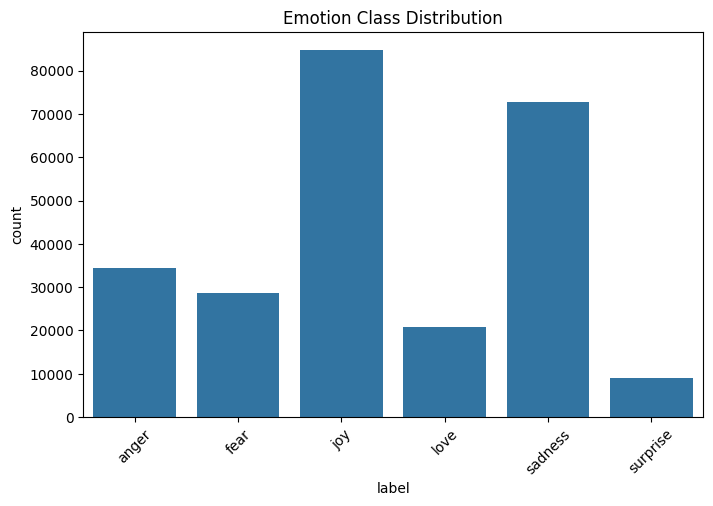

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='label')
plt.title('Emotion Class Distribution')
plt.xticks(rotation=45)
plt.show()


Data Imbalanced

Kelas joy merupakan kelas dominan dengan jumlah data paling besar.

Kelas sadness juga memiliki jumlah sampel yang tinggi.

Kelas surprise merupakan kelas dengan jumlah data paling sedikit.

Kelas anger, fear, dan love berada pada kategori menengah.

Ketidakseimbangan kelas ini berpotensi menyebabkan model lebih bias terhadap kelas mayoritas dan menurunkan performa prediksi pada kelas minoritas, terutama surprise.

In [10]:
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))
df['text_length'].describe()

,text_length
count,250084.000000
mean,19.211337
std,11.054051
min,1.000000
25%,11.000000
50%,17.000000
75%,25.000000
max,178.000000


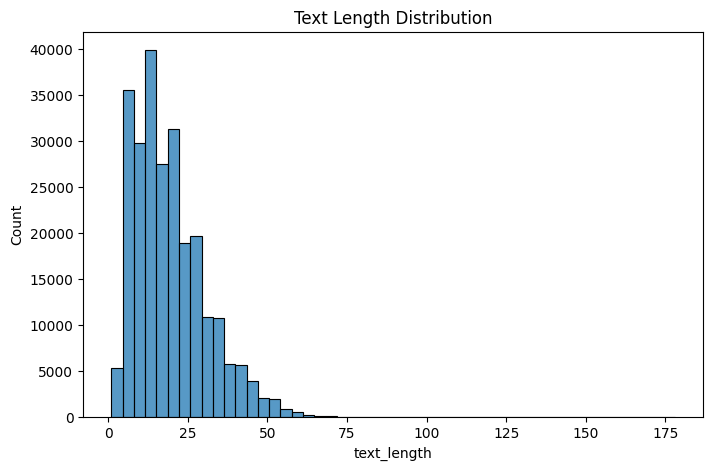

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(df['text_length'], bins=50)
plt.title('Text Length Distribution')
plt.show()


Distribusi menunjukkan pola right-skewed, di mana sebagian besar teks pendek dan hanya sedikit teks yang sangat panjang.

Variasi panjang teks yang cukup besar menunjukkan adanya teks yang sangat pendek dengan konteks terbatas serta teks yang sangat panjang yang berpotensi mengandung noise.

- Diperlukan padding dan truncation

- Pemilihan maksimum sequence length harus mempertimbangkan trade-off antara efisiensi komputasi dan pelestarian informasi

In [12]:
df.groupby('label')['text_length'].mean()

,text_length
label,
anger,19.031957
fear,18.981835
joy,19.533767
love,20.784536
sadness,18.490084
surprise,19.798731


### 2b. Based on the discovered issues, pre-process the text data to reduce noises in the data!

In [13]:
import pandas as pd
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize


In [14]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [15]:
stop_words = set(stopwords.words('english'))
# stopwords = kata umum (is, am, the, and) → tidak membawa makna emosi

lemmatizer = WordNetLemmatizer()
# lemmatizer = mengubah kata ke bentuk dasar (feels → feel)


In [16]:
def preprocess_text(text):
    """
    Fungsi ini digunakan untuk membersihkan teks
    agar noise berkurang dan siap digunakan untuk modeling
    """

    # 1. Case folding
    # Mengubah semua huruf menjadi lowercase
    # Tujuan: menyamakan bentuk kata (Happy = happy)
    text = text.lower()

    # 2. Remove URL
    # Menghapus link karena tidak relevan untuk analisis emosi
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    # 3. Remove numbers
    # Angka biasanya tidak membawa informasi emosi
    text = re.sub(r'\d+', '', text)

    # 4. Remove punctuation & special characters
    # Menghapus tanda baca dan simbol (!@#$)
    text = re.sub(r'[^\w\s]', '', text)

    # 5. Tokenization
    # Memecah kalimat menjadi kata-kata
    tokens = word_tokenize(text)

    # 6. Stopword removal
    # Menghapus kata umum yang tidak bermakna emosional
    tokens = [word for word in tokens if word not in stop_words]

    # 7. Lemmatization
    # Mengubah kata ke bentuk dasarnya
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # 8. Join token kembali menjadi kalimat
    text = ' '.join(tokens)

    return text


In [17]:
df['clean_text'] = df['text'].apply(preprocess_text)

In [18]:
# 5. Hitung panjang teks setelah preprocessing

df['clean_text_length'] = df['clean_text'].apply(lambda x: len(x.split()))


In [19]:
# 6. Drop baris dengan clean_text kosong

df = df[df['clean_text'].str.strip() != '']


In [20]:
# Lihat 5 contoh sebelum & sesudah preprocessing
df[['text', 'clean_text']].head()


,text,clean_text
0,i feel rebellious and i like it,feel rebellious like
1,i feel completely agitated and full of blame,feel completely agitated full blame
2,i feel like a witch bc im aggravated and i wan...,feel like witch bc im aggravated want go like ...
3,i feel really bitchy for doing this but im rea...,feel really bitchy im really iffy read journal...
4,i feel rude but i move past it immediately,feel rude move past immediately


In [21]:
df['text_length'] = df['text'].apply(lambda x: len(x.split()))
df['clean_text_length'] = df['clean_text'].apply(lambda x: len(x.split()))

df[['text_length', 'clean_text_length']].describe()


,text_length,clean_text_length
count,250074.000000,250074.000000
mean,19.212041,9.355351
std,11.053709,5.240527
min,1.000000,1.000000
25%,11.000000,5.000000
50%,17.000000,8.000000
75%,25.000000,12.000000
max,178.000000,79.000000


In [22]:
# Jumlah teks kosong
(df['clean_text'].str.strip() == '').sum()

np.int64(0)

In [23]:
# Unique words sebelum preprocessing
vocab_before = set(" ".join(df['text']).split())

# Unique words sesudah preprocessing
vocab_after = set(" ".join(df['clean_text']).split())

print("Vocabulary before:", len(vocab_before))
print("Vocabulary after :", len(vocab_after))


Vocabulary before: 59108
Vocabulary after : 52841


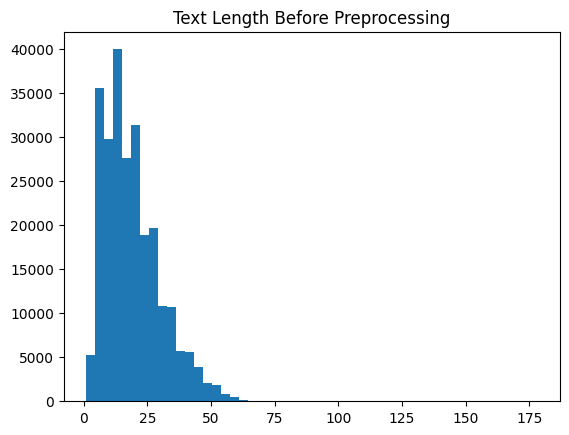

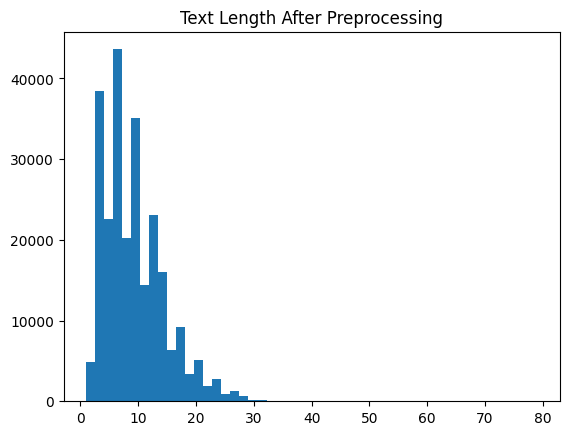

In [24]:
import matplotlib.pyplot as plt

plt.hist(df['text_length'], bins=50)
plt.title("Text Length Before Preprocessing")
plt.show()

plt.hist(df['clean_text_length'], bins=50)
plt.title("Text Length After Preprocessing")
plt.show()


Distribusi panjang teks setelah preprocessing tetap menunjukkan pola right-skewed yang serupa dengan data awal. Hal ini menunjukkan bahwa preprocessing tidak mengubah karakteristik alami data, melainkan hanya menghilangkan noise seperti stopwords dan karakter tidak relevan, sehingga struktur semantik utama tetap terjaga.

###2d. Load a pre-trained BERT-based model (e.g. DistilBERT, RoBERTa, etc,) and train it on the same dataset for at least 15 epochs & analyze the train-validation losses!

In [25]:
!pip install -U transformers datasets torch scikit-learn matplotlib

In [26]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification, Trainer, TrainingArguments

In [27]:
le = LabelEncoder()
y = le.fit_transform(df['label'])
num_labels = len(np.unique(y))

In [28]:
model_name = "distilbert-base-uncased"
max_len = 40

tokenizer = DistilBertTokenizerFast.from_pretrained(model_name)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

In [29]:
X_train, X_val, y_train, y_val = train_test_split(
    df['clean_text'].tolist(),
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train[:10000]
y_train = y_train[:10000]

X_val = X_val[:2000]
y_val = y_val[:2000]

train_enc = tokenizer(
    X_train,
    truncation=True,
    padding='max_length',
    max_length=max_len
)

val_enc = tokenizer(
    X_val,
    truncation=True,
    padding='max_length',
    max_length=max_len
)

In [30]:
class TextDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)


In [31]:
train_dataset = TextDataset(train_enc, y_train)
val_dataset = TextDataset(val_enc, y_val)


In [32]:
model = DistilBertForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_labels
)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [33]:
for param in model.distilbert.parameters():
    param.requires_grad = False

In [34]:
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=15,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=3e-5,
    save_strategy="no",
    report_to="none"
)

In [35]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer
)

history = trainer.train()

/tmp/ipython-input-395195413.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Step,Training Loss
500,1.558800
1000,1.441300
1500,1.377000
2000,1.348500
2500,1.318000
3000,1.295200
3500,1.263300
4000,1.270200
4500,1.253000
5000,1.237100


In [36]:
trainer.state.log_history


[{'loss': 1.5588,
  'grad_norm': 1.8094019889831543,
  'learning_rate': 2.8403200000000003e-05,
  'epoch': 0.8,
  'step': 500},
 {'loss': 1.4413,
  'grad_norm': 1.581123948097229,
  'learning_rate': 2.68032e-05,
  'epoch': 1.6,
  'step': 1000},
 {'loss': 1.377,
  'grad_norm': 2.1292080879211426,
  'learning_rate': 2.52032e-05,
  'epoch': 2.4,
  'step': 1500},
 {'loss': 1.3485,
  'grad_norm': 3.5442657470703125,
  'learning_rate': 2.36032e-05,
  'epoch': 3.2,
  'step': 2000},
 {'loss': 1.318,
  'grad_norm': 2.629668712615967,
  'learning_rate': 2.20032e-05,
  'epoch': 4.0,
  'step': 2500},
 {'loss': 1.2952,
  'grad_norm': 3.7378549575805664,
  'learning_rate': 2.0403199999999998e-05,
  'epoch': 4.8,
  'step': 3000},
 {'loss': 1.2633,
  'grad_norm': 2.5936901569366455,
  'learning_rate': 1.88032e-05,
  'epoch': 5.6,
  'step': 3500},
 {'loss': 1.2702,
  'grad_norm': 2.233583688735962,
  'learning_rate': 1.7203199999999998e-05,
  'epoch': 6.4,
  'step': 4000},
 {'loss': 1.253,
  'grad_norm

Epoch 1


Step,Training Loss
500,1.207000
1000,1.190200
1500,1.175800
2000,1.190200
2500,1.174500
3000,1.165500
3500,1.154300
4000,1.166700
4500,1.159300
5000,1.144100


Epoch 2


Step,Training Loss
500,1.138400
1000,1.127000
1500,1.119600
2000,1.130400
2500,1.120900
3000,1.114400
3500,1.097400
4000,1.111800
4500,1.107100
5000,1.101200


Epoch 3


...

Step,Training Loss
500,0.939200
1000,0.933400
1500,0.920600
2000,0.940100
2500,0.930600
3000,0.920500
3500,0.914700
4000,0.936800
4500,0.926600
5000,0.925900


Epoch 14


Step,Training Loss
500,0.929100
1000,0.924100
1500,0.908200
2000,0.928300
2500,0.918200
3000,0.914500
3500,0.900900
4000,0.923100
4500,0.911300
5000,0.908800


Epoch 15


Step,Training Loss
500,0.906100
1000,0.918100
1500,0.903600
2000,0.916000
2500,0.907900
3000,0.898200
3500,0.888200
4000,0.917600
4500,0.908100
5000,0.892900


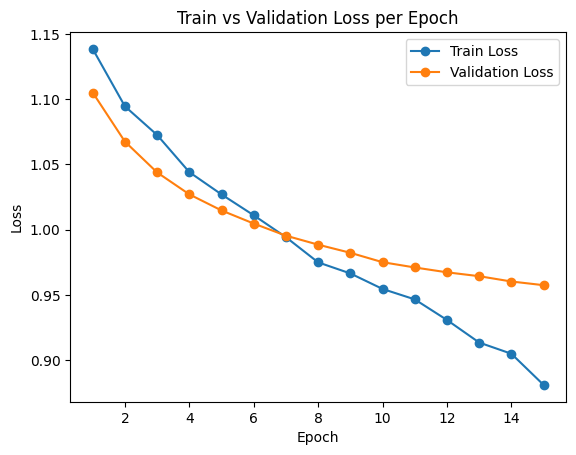

In [37]:
from transformers import Trainer

train_losses = []
val_losses = []

for epoch in range(15):
    print(f"Epoch {epoch+1}")

    # train satu epoch
    trainer.train(resume_from_checkpoint=None)

    # ambil training loss terakhir dari log_history
    logs = trainer.state.log_history
    last_train_loss = [l["loss"] for l in logs if "loss" in l][-1]
    train_losses.append(last_train_loss)

    # evaluasi validation
    eval_result = trainer.evaluate()
    val_losses.append(eval_result["eval_loss"])

# Plot per epoch
import matplotlib.pyplot as plt

plt.plot(range(1,16), train_losses, marker='o', label="Train Loss")
plt.plot(range(1,16), val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss per Epoch")
plt.legend()
plt.show()

In [38]:
eval_result = trainer.evaluate()
print(eval_result)

{'eval_loss': 0.957393229007721, 'eval_runtime': 2.4431, 'eval_samples_per_second': 818.628, 'eval_steps_per_second': 51.164, 'epoch': 15.0}


###2e. Evaluate both models on a test dataset. Analyze the results & make a clear conclusion!

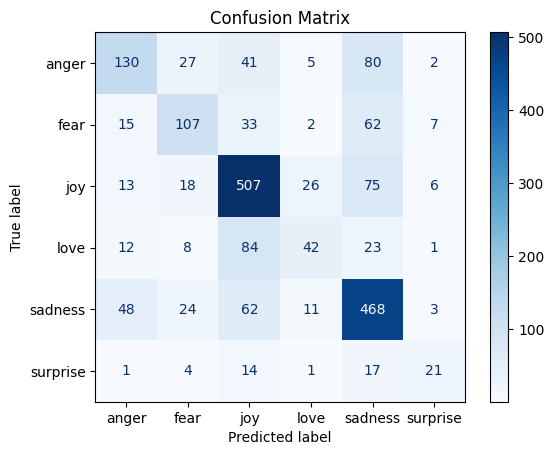

In [41]:
import torch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# pindahkan val_enc ke device
val_inputs = {k: torch.tensor(v).to(device) for k,v in val_enc.items()}

with torch.no_grad():
    outputs = model(**val_inputs)
    preds = torch.argmax(outputs.logits, dim=-1).cpu().numpy()  # pindah ke CPU

# confusion matrix
cm = confusion_matrix(y_val, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [42]:
from sklearn.metrics import classification_report, accuracy_score

print("Accuracy:", accuracy_score(y_val, preds))
print("\nClassification Report:")
print(classification_report(y_val, preds, target_names=le.classes_))


Accuracy: 0.6375

Classification Report:
              precision    recall  f1-score   support

       anger       0.59      0.46      0.52       285
        fear       0.57      0.47      0.52       226
         joy       0.68      0.79      0.73       645
        love       0.48      0.25      0.33       170
     sadness       0.65      0.76      0.70       616
    surprise       0.53      0.36      0.43        58

    accuracy                           0.64      2000
   macro avg       0.58      0.51      0.54      2000
weighted avg       0.62      0.64      0.62      2000



Akurasi validasi model sebesar 63,75%. Kinerja terbaik ada di kelas joy dan sadness, yang memiliki jumlah data lebih besar dan ciri dari text yang lebih jelas. Sebaliknya, kelas love dan surprise menunjukkan nilai recall yang rendah akibat jumlah data yang sedikit serta tumpang tindih makna antar emosi. Kesimpulannya, model masih mengalami kesulitan dalam membedakan emosi yang memiliki kedekatan semantik.